In [14]:
# conda env 'vis2'

import netCDF4 as nc
import xarray as xr
import at3d
import matplotlib.pyplot as plt
import numpy as np

In [15]:
obs_small_file = '../data/CAMP2Ex_RF17_MISR_OBS_001.nc'
obs_small = xr.load_dataset(obs_small_file)
obs_file = '../../dev/CAMP2Ex_RF17_MISR_OBS_002.nc'
obs = xr.load_dataset(obs_file)

aerosol_file = '../../data/MISR/MISR_AM1_AS_AEROSOL_P117_O105254_F13_0023.nc'

dataset = nc.Dataset(aerosol_file,'r')
products = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/']))
aux = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/AUXILIARY/']))
merged = xr.merge([products, aux])
aerosol_ds = merged.sel(X_Dim=slice(1.774e7,1.816e7), Y_Dim=slice(-0.6e6, 0.6e6)).copy(deep=True)
aerosol_ds['Aerosol_Optical_Depth_Relative_Uncertainty'] = 100*(aerosol_ds.Aerosol_Optical_Depth_Uncertainty / aerosol_ds.Aerosol_Optical_Depth)

In [3]:
aerosol_ds

<xarray.Dataset>
Dimensions:                                            (X_Dim: 96, Y_Dim: 272,
                                                        Mixture_Dim: 74,
                                                        Spectral_AOD_Scaling_Coeff_Dim: 3,
                                                        Block_Number: 125,
                                                        Camera_Dim: 9)
Coordinates:
  * X_Dim                                              (X_Dim) float64 1.774e...
  * Y_Dim                                              (Y_Dim) float64 -5.968...
  * Mixture_Dim                                        (Mixture_Dim) int32 1 ...
  * Spectral_AOD_Scaling_Coeff_Dim                     (Spectral_AOD_Scaling_Coeff_Dim) int32 ...
  * Block_Number                                       (Block_Number) int32 2...
    Time                                               (X_Dim) datetime64[ns] ...
  * Camera_Dim                                         (Camera_Dim) int32 1 ....
    Latitude                                           (X_Dim, Y_Dim) float32 ...
    Longitude                                          (X_Dim, Y_Dim) float32 ...
Data variables: (12/46)
    Block_Start_X_Index                                (Block_Number) int32 ...
    Block_Start_Y_Index                                (Block_Number) int32 ...
    Elevation                                          (X_Dim, Y_Dim) float32 ...
    Year                                               (X_Dim, Y_Dim) float32 ...
    Day_Of_Year                                        (X_Dim, Y_Dim) float32 ...
    Month                                              (X_Dim, Y_Dim) float32 ...
    ...                                                 ...
    Column_Ozone_Climatology                           (X_Dim, Y_Dim) float32 ...
    Ocean_Surface_Wind_Speed_Climatology               (X_Dim, Y_Dim) float32 ...
    Ocean_Surface_Wind_Speed_Retrieved                 (X_Dim, Y_Dim) float32 ...
    Rayleigh_Optical_Depth                             (X_Dim, Y_Dim) float32 ...
    Lowest_Residual_Mixture                            (X_Dim, Y_Dim) float64 ...
    Aerosol_Optical_Depth_Relative_Uncertainty         (X_Dim, Y_Dim) float32 ...
Attributes:
    GCTP_projection_parameters:  [ 6.37813700e+06 -6.69434800e-03  0.00000000...
    resolution_in_meters:        4400
    block_size_in_lines:         32
    block_size_in_samples:       128

In [4]:
obs

<xarray.Dataset>
Dimensions:     (camera: 9, y275: 1536, x275: 2176, y17600: 24, x17600: 34)
Coordinates:
  * camera      (camera) object 'DF' 'CF' 'BF' 'AF' 'AN' 'AA' 'BA' 'CA' 'DA'
Dimensions without coordinates: y275, x275, y17600, x17600
Data variables: (12/15)
    brf         (camera, y275, x275) float64 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    lat275      (y275, x275) float64 -200.0 -200.0 -200.0 ... -200.0 -200.0
    lon275      (y275, x275) float64 -200.0 -200.0 -200.0 ... -200.0 -200.0
    lat17600    (y17600, x17600) float64 -200.0 -200.0 21.45 ... -200.0 -200.0
    lon17600    (y17600, x17600) float64 -200.0 -200.0 118.2 ... -200.0 -200.0
    SZA         (y17600, x17600) float64 -555.0 -555.0 -444.0 ... -555.0 -555.0
    ...          ...
    VZA_center  (camera) float64 70.2 60.05 45.65 26.12 ... 45.63 60.1 70.43
    VAA_center  (camera) float64 15.51 15.97 16.65 18.17 ... 194.4 195.0 195.3
    SZA_center  float64 28.45
    SAA_center  float64 321.9
    center_lat  float64 19.44
    center_lon  float64 120.5
Attributes:
    orbit:    105254
    path:     117
    blocks:   [74 76]

(17.4, 21.5)

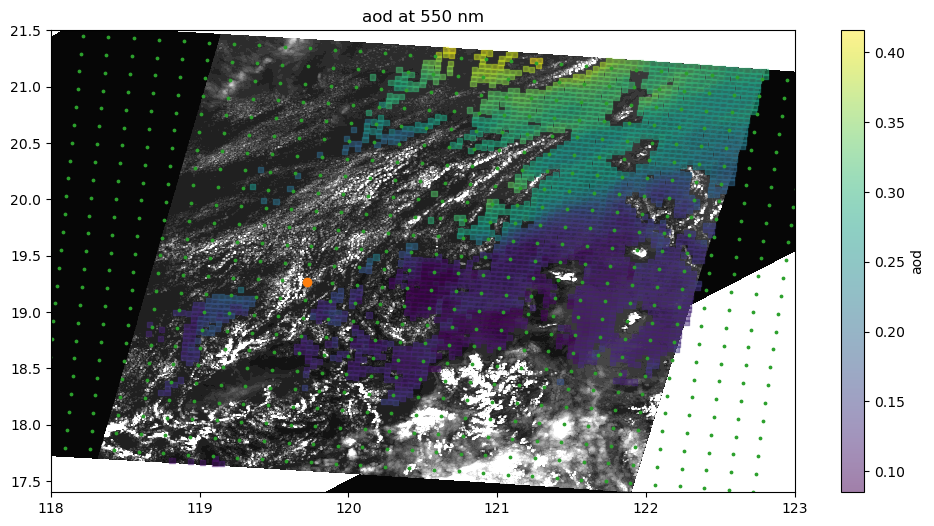

In [7]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod = aerosol_ds.Aerosol_Optical_Depth.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod')
ax.set_title('aod at 550 nm')
ax.set_xlim([118, 123])
ax.set_ylim([17.4, 21.5])

(17.4, 21.5)

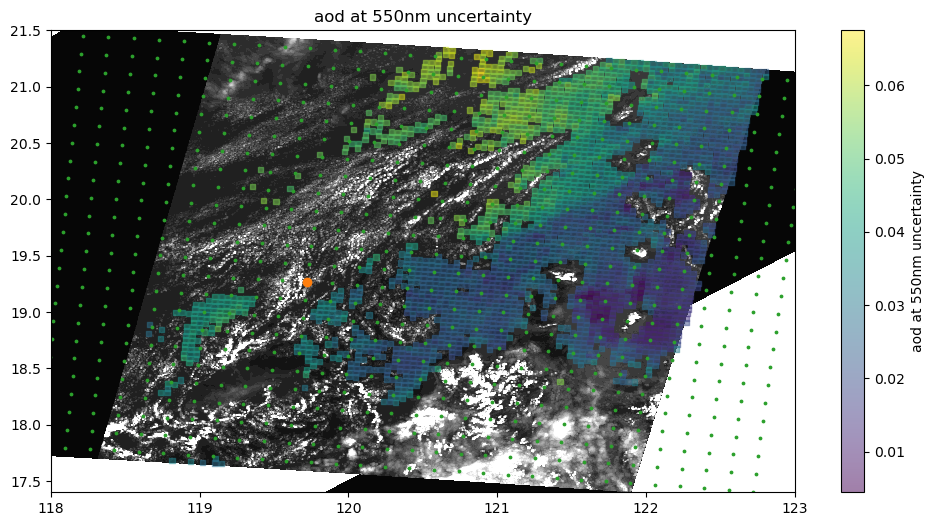

In [8]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod_u = aerosol_ds.Aerosol_Optical_Depth_Uncertainty.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod_u, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod at 550nm uncertainty')
ax.set_title('aod at 550nm uncertainty')
ax.set_xlim([118, 123])
ax.set_ylim([17.4, 21.5])

(17.0, 21.5)

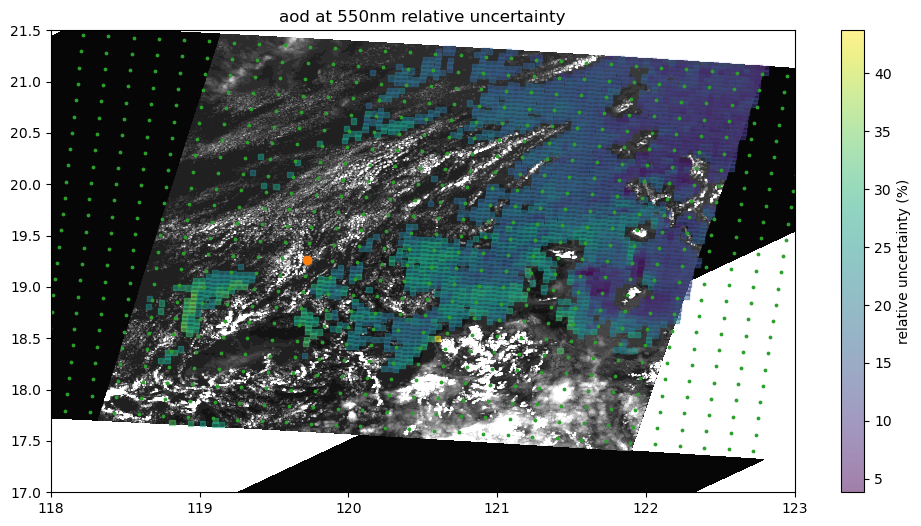

In [9]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod_ru = aerosol_ds.Aerosol_Optical_Depth_Relative_Uncertainty.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod_ru, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='relative uncertainty (%)')
ax.set_title('aod at 550nm relative uncertainty')
ax.set_xlim([118, 123])
ax.set_ylim([17, 21.5])

(17.0, 21.5)

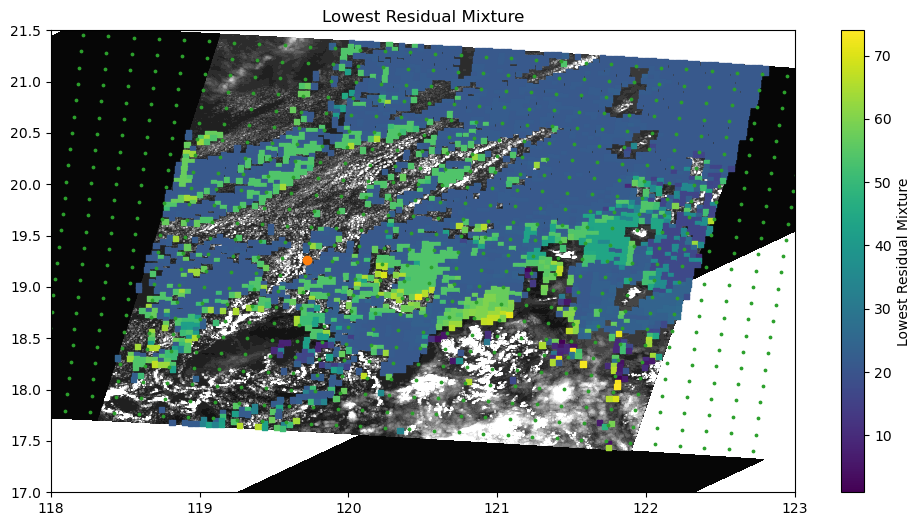

In [10]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
lrm = aerosol_ds.Lowest_Residual_Mixture.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=lrm, s=14, alpha=1.0, marker='s')
plt.colorbar(c, ax=ax, label='Lowest Residual Mixture')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
ax.set_title('Lowest Residual Mixture')
ax.set_xlim([118, 123])
ax.set_ylim([17, 21.5])

Text(0.5, 1.0, 'Lowest Residual Mixture')

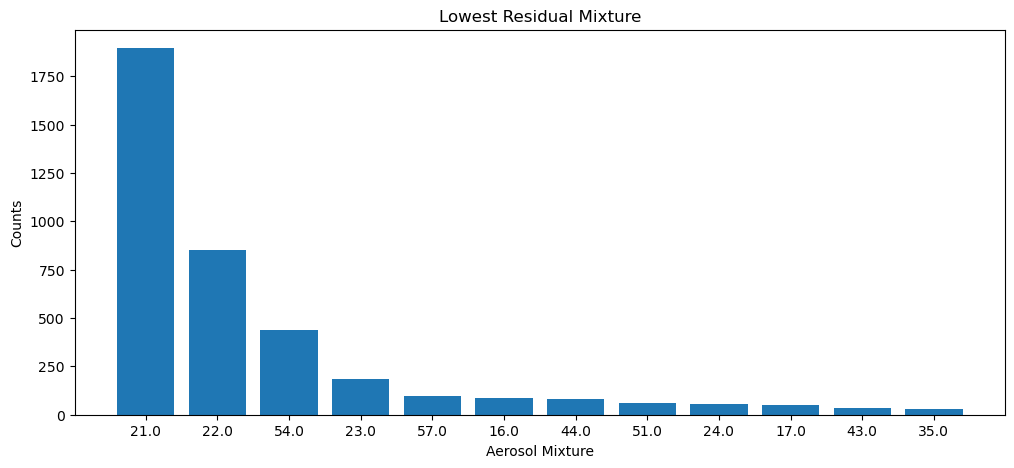

In [12]:
n_mixtures = 12
hist, bin_edges = np.histogram(aerosol_ds.Lowest_Residual_Mixture.data, bins=74, range=(0.5, 74.5))
midpoints = (bin_edges[:-1] + bin_edges[1:])/2
sorted_hist = np.sort(hist)
sorted_hist = sorted_hist[::-1]
sorted_midpoints = midpoints[np.argsort(hist)]
sorted_midpoints = sorted_midpoints[::-1]
f, ax = plt.subplots(1, 1, figsize=(12,5))
ax.bar(sorted_midpoints.astype('str')[:n_mixtures], sorted_hist[:n_mixtures])
ax.set_xlabel('Aerosol Mixture')
ax.set_ylabel('Counts')
ax.set_title('Lowest Residual Mixture')

(17.4, 21.5)

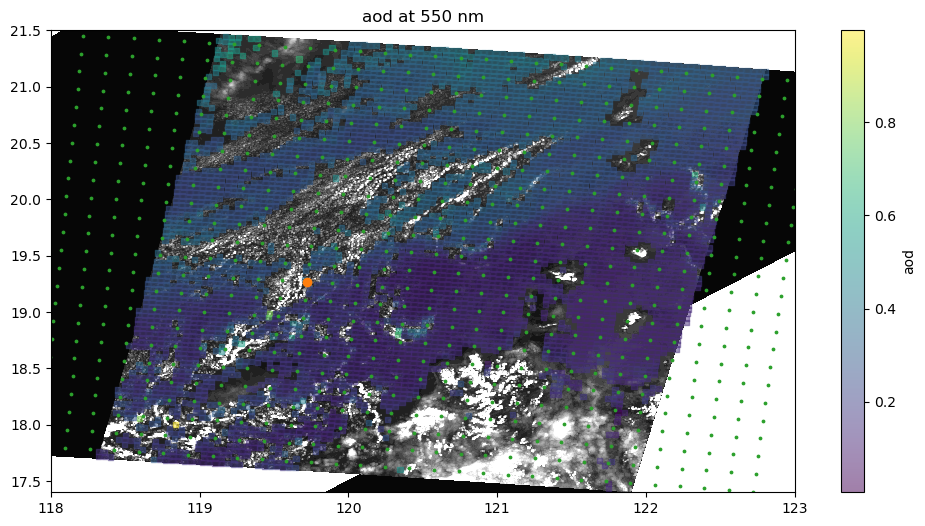

In [13]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod_21 = aerosol_ds.sel(Mixture_Dim=21).Aerosol_Optical_Depth_Per_Mixture.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod_21, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod')
ax.set_title('aod at 550 nm')
ax.set_xlim([118, 123])
ax.set_ylim([17.4, 21.5])